# Fit a logistic growth model

Fits a logistic curve with a constant offset to the mean optical density, then saves the parameters and a figure.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

PROCESSED = Path("../data/processed/ecoli-growth-37c-1pct-clean.csv")
FIGURE = Path("../results/figures/growth_curve_fit.png")
TABLE = Path("../results/tables/fit_parameters.csv")

data = pd.read_csv(PROCESSED)
time = data["time_min"].to_numpy()
od = data["od_mean"].to_numpy()

The model: `od(t) = offset + capacity / (1 + exp(-rate * (t - midpoint)))`. The steepest slope of this curve is `capacity * rate / 4`, reached at the midpoint.

In [2]:
def logistic(t, offset, capacity, rate, midpoint):
    return offset + capacity / (1 + np.exp(-rate * (t - midpoint)))


start = [od.min(), od.max() - od.min(), 0.02, 100]
values, covariance = curve_fit(logistic, time, od, p0=start)
errors = np.sqrt(np.diag(covariance))

residuals = od - logistic(time, *values)
r_squared = 1 - (residuals**2).sum() / ((od - od.mean()) ** 2).sum()

parameters = pd.DataFrame(
    {
        "parameter": ["offset", "capacity", "rate_per_min", "midpoint_min"],
        "value": values,
        "standard_error": errors,
    }
)
parameters.to_csv(TABLE, index=False)

print(f"R squared: {r_squared:.3f}")
print(f"Steepest slope: {values[1] * values[2] / 4:.4f} OD per minute")
parameters

R squared: 0.981
Steepest slope: 0.0026 OD per minute


,parameter,value,standard_error
0,offset,0.084883,0.012078
1,capacity,0.465759,0.012227
2,rate_per_min,0.022668,0.000920
3,midpoint_min,102.093372,3.141699


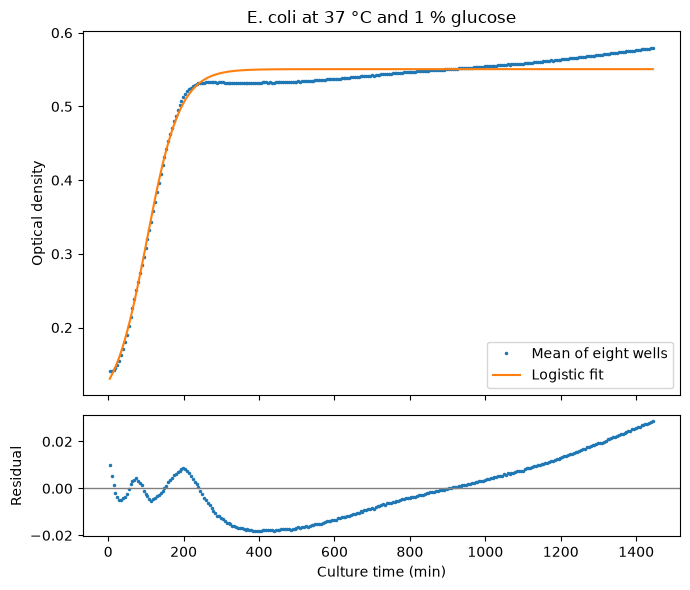

In [3]:
fig, (top, bottom) = plt.subplots(2, 1, figsize=(7, 6), sharex=True, height_ratios=[3, 1])

top.plot(time, od, ".", markersize=3, label="Mean of eight wells")
top.plot(time, logistic(time, *values), label="Logistic fit")
top.set_ylabel("Optical density")
top.set_title("E. coli at 37 °C and 1 % glucose")
top.legend()

bottom.plot(time, residuals, ".", markersize=3)
bottom.axhline(0, color="gray", linewidth=1)
bottom.set_xlabel("Culture time (min)")
bottom.set_ylabel("Residual")

fig.tight_layout()
fig.savefig(FIGURE, dpi=150)